## 0. Setup & Data Cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.rcParams['figure.dpi'] = 100

# Superstore CSV is exported with Windows-1252 / Latin-1 encoding, not UTF-8
df = pd.read_csv('Sample_-_Superstore.csv', encoding='cp1252')

df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date']  = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')

# basic cleaning: drop exact duplicate rows, standardize text columns
df = df.drop_duplicates()
for c in ['Ship Mode', 'Segment', 'Region', 'Category', 'Sub-Category']:
    df[c] = df[c].str.strip()

print(df.shape)
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
# Save a cleaned copy for submission
df.to_csv('Superstore_cleaned.csv', index=False)
print("Saved Superstore_cleaned.csv with", len(df), "rows")

Saved Superstore_cleaned.csv with 9994 rows


In [3]:
# Reusable aggregates used throughout the notebook
monthly_sales = (df.set_index('Order Date')['Sales']
                    .resample('MS').sum()
                    .rename('Total Sales'))
monthly_sales.index = monthly_sales.index.strftime('%Y-%m')

monthly_profit = (df.set_index('Order Date')['Profit']
                     .resample('MS').sum()
                     .rename('Total Profit'))
monthly_profit.index = monthly_profit.index.strftime('%Y-%m')

top5_subcat = (df.groupby('Sub-Category')['Sales'].sum()
                 .sort_values(ascending=False).head(5))

region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

region_cat = df.pivot_table(index='Region', columns='Category',
                             values='Sales', aggfunc='sum')

subcat_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values()

monthly_sales.head(), region_sales, subcat_profit.head()

(Order Date
 2014-01    14236.895
 2014-02     4519.892
 2014-03    55691.009
 2014-04    28295.345
 2014-05    23648.287
 Name: Total Sales, dtype: float64,
 Region
 West       725457.8245
 East       678781.2400
 Central    501239.8908
 South      391721.9050
 Name: Sales, dtype: float64,
 Sub-Category
 Tables      -17725.4811
 Bookcases    -3472.5560
 Supplies     -1189.0995
 Fasteners      949.5182
 Machines      3384.7569
 Name: Profit, dtype: float64)

## Task 1 — Same data, three chart types
Monthly sales, plotted as a bar chart, a line chart, and a pie chart.

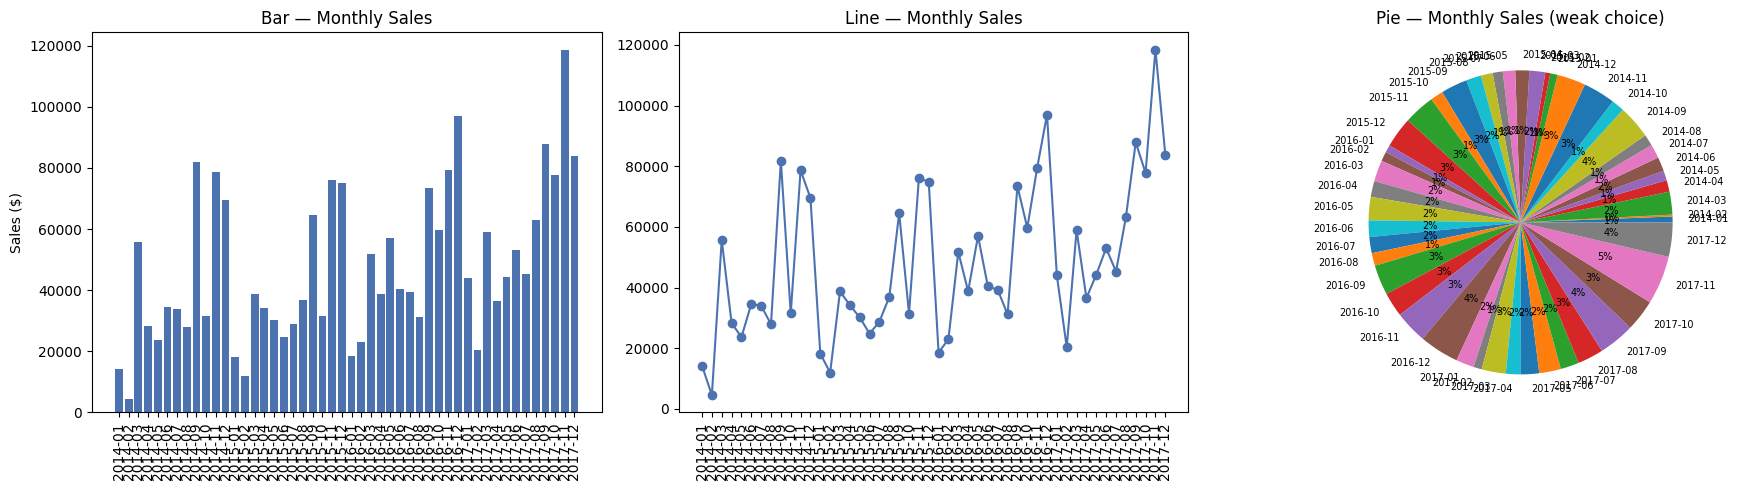

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Bar
axes[0].bar(monthly_sales.index, monthly_sales.values, color='#4C72B0')
axes[0].set_title('Bar — Monthly Sales')
axes[0].tick_params(axis='x', rotation=90)
axes[0].set_ylabel('Sales ($)')

# Line
axes[1].plot(monthly_sales.index, monthly_sales.values, marker='o', color='#4C72B0')
axes[1].set_title('Line — Monthly Sales')
axes[1].tick_params(axis='x', rotation=90)

# Pie (too many slices on purpose, to show why it fails here)
axes[2].pie(monthly_sales.values, labels=monthly_sales.index, autopct='%1.0f%%',
            textprops={'fontsize': 7})
axes[2].set_title('Pie — Monthly Sales (weak choice)')

plt.tight_layout()
plt.show()

**Which chart shows the trend best, and which one hides it? Why?**

The **line chart** shows the trend best: the eye follows the connected points across time and
immediately reads the seasonal dips/rises (e.g., the year-end spike). The **bar chart** is a
reasonable second choice — it still preserves the left-to-right time ordering, just with less
emphasis on the *rate of change* between points.

The **pie chart hides the trend completely**. A pie encodes *part-to-whole* relationships, not
*order over time* — slices are arranged around a circle with no inherent time axis, there are far
more than the ~4-slice limit a pie can handle legibly, and adjacent months end up as
similar-sized, similarly-colored wedges that are almost impossible to compare precisely. Time
series data has no "whole" that months are naturally a percentage of, so the pie is the wrong
encoding for this task entirely.

## Task 2 — Choosing the right chart for each statement

### 2a. "Compare total sales across the top 5 sub-categories." → Bar chart

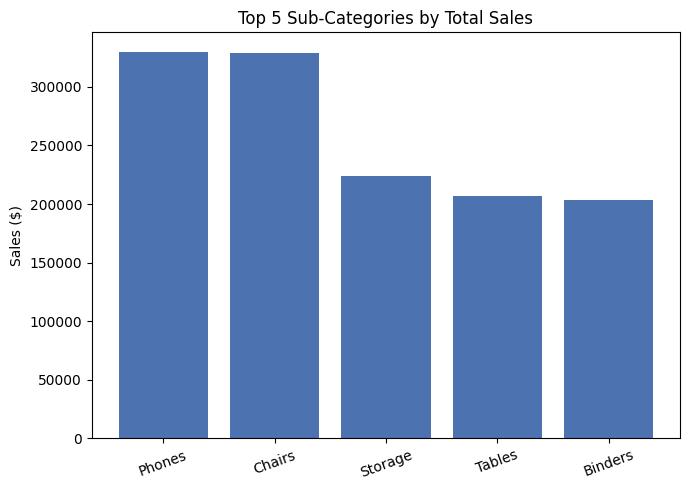

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(top5_subcat.index, top5_subcat.values, color='#4C72B0')
ax.set_title('Top 5 Sub-Categories by Total Sales')
ax.set_ylabel('Sales ($)')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

**Why bar fits / why pie (weak choice) would underperform:** A bar chart lets the reader compare
five discrete category totals by bar *height*, which the human eye judges far more precisely than
the *angle* of a pie slice. With 5 categories a pie is borderline-usable, but it still can't
support the precise value comparison the task asks for ("compare total sales") — bars can be read
against a shared axis to the nearest gridline, wedges cannot.

### 2b. "Show the revenue trend over time." → Line chart

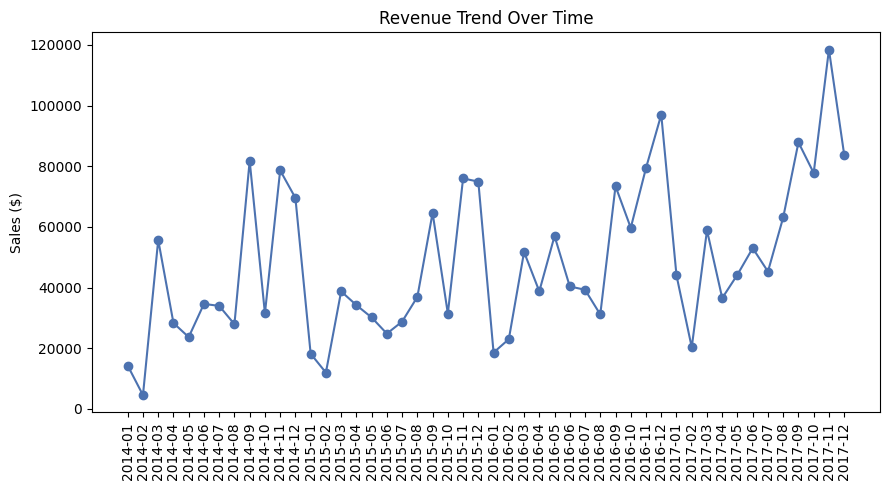

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(monthly_sales.index, monthly_sales.values, marker='o', color='#4C72B0')
ax.set_title('Revenue Trend Over Time')
ax.set_ylabel('Sales ($)')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

**Why line fits / why bar (weak choice) would underperform:** With this many time points, a line
chart's continuous stroke makes the *direction and rate* of change immediately visible. A bar
chart of the same series works, but with many bars packed side by side the shape of the trend gets
visually chopped into disconnected columns, and the eye has to do more work to reconstruct the
slope between periods — the task explicitly names *trend*, which is a line's strength.

### 2c. "Show the distribution of order-line sales values." → Histogram

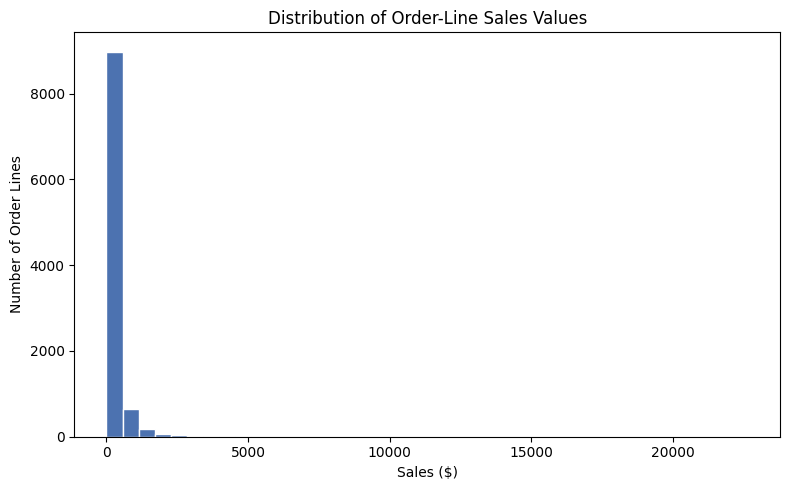

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df['Sales'], bins=40, color='#4C72B0', edgecolor='white')
ax.set_title('Distribution of Order-Line Sales Values')
ax.set_xlabel('Sales ($)')
ax.set_ylabel('Number of Order Lines')
plt.tight_layout()
plt.show()

**Why histogram fits / why bar-of-averages (weak choice) would underperform:** A histogram bins
the raw, un-aggregated Sales values and shows how many order lines fall into each range, exposing
the shape of the distribution (here, a strong right skew with many small orders and a long tail of
large ones). A "bar of averages" would collapse all of that into a single summary number and
throw away the spread, skew, and outliers — exactly the information distribution questions need.

### 2d. "Show the relationship between discount level and profit." → Scatter plot

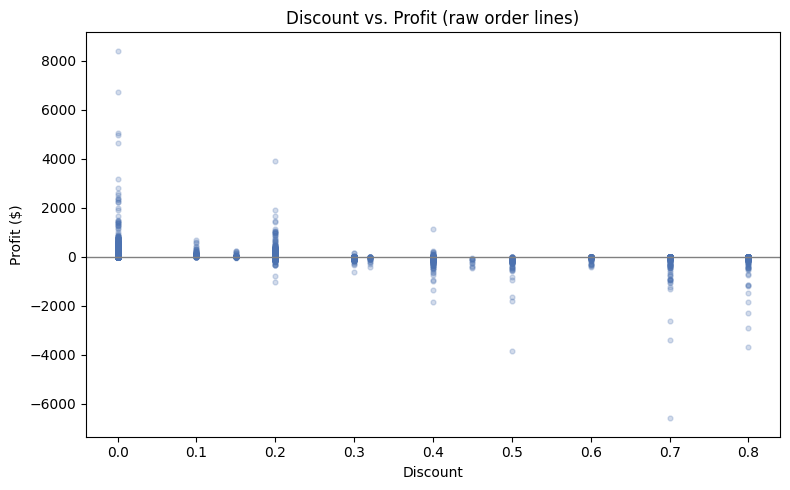

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['Discount'], df['Profit'], alpha=0.25, s=12, color='#4C72B0')
ax.axhline(0, color='gray', linewidth=1)
ax.set_title('Discount vs. Profit (raw order lines)')
ax.set_xlabel('Discount')
ax.set_ylabel('Profit ($)')
plt.tight_layout()
plt.show()

**Why scatter fits / why line (weak choice) would underperform:** Discount and Profit are two
independent, continuous, unaggregated numeric variables per order line — a scatter plot is built
exactly for showing correlation between two such variables, and the point cloud below reveals that
profit turns negative once discounts get large. A line chart implies a single ordered path through
the data and would require artificially sorting or averaging by discount level, hiding the real
spread and any non-linear relationship in the raw data.

## Task 3 — Color selection

### 3a. Region sales — categorical palette

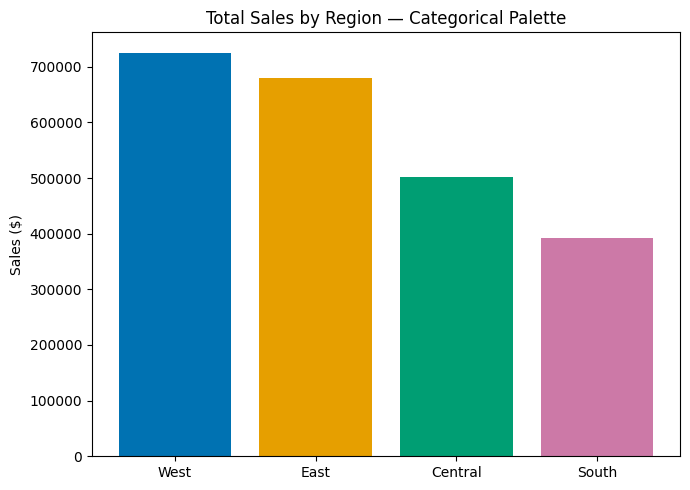

In [9]:
# Fixed, distinguishable categorical palette (colorblind-safe, Okabe-Ito based)
categorical_palette = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(region_sales.index, region_sales.values, color=categorical_palette[:len(region_sales)])
ax.set_title('Total Sales by Region — Categorical Palette')
ax.set_ylabel('Sales ($)')
plt.tight_layout()
plt.show()

### 3b. Region × Category — heatmap with sequential palette

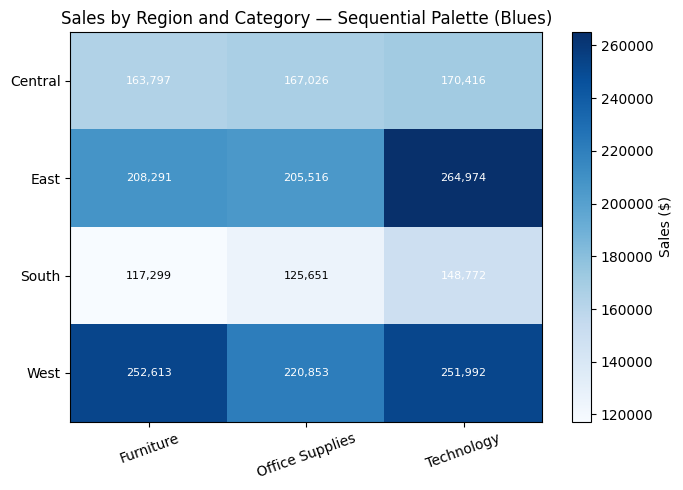

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(region_cat.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(region_cat.columns)))
ax.set_xticklabels(region_cat.columns, rotation=20)
ax.set_yticks(range(len(region_cat.index)))
ax.set_yticklabels(region_cat.index)
ax.set_title('Sales by Region and Category — Sequential Palette (Blues)')
for i in range(region_cat.shape[0]):
    for j in range(region_cat.shape[1]):
        val = region_cat.values[i, j]
        ax.text(j, i, f'{val:,.0f}', ha='center', va='center',
                color='white' if val > region_cat.values.max()*0.55 else 'black', fontsize=8)
fig.colorbar(im, ax=ax, label='Sales ($)')
plt.tight_layout()
plt.show()

### 3c. Monthly profit — diverging palette (crosses zero)

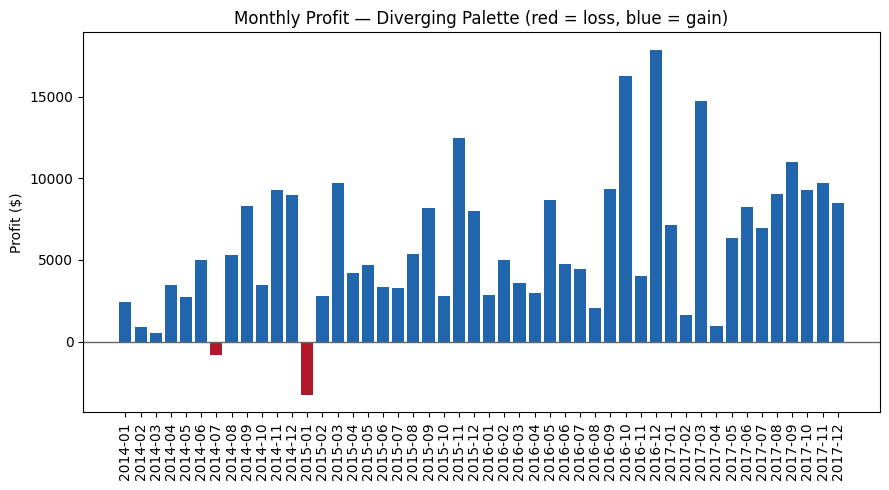

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#B2182B' if v < 0 else '#2166AC' for v in monthly_profit.values]  # diverging, meets at gray/zero
ax.bar(monthly_profit.index, monthly_profit.values, color=colors)
ax.axhline(0, color='#666666', linewidth=1)
ax.set_title('Monthly Profit — Diverging Palette (red = loss, blue = gain)')
ax.set_ylabel('Profit ($)')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

Each palette above matches the color-selection guidance: **categorical** for the four
unordered regions (fixed, distinguishable hues, no implied order), **sequential** (single hue,
light→dark) for the region-by-category magnitudes, and **diverging** (two hues meeting at a
neutral zero-line) for profit, which genuinely crosses a meaningful midpoint.

## Task 4 — Contrast ratio & colorblind accessibility check

### 4a. WCAG contrast ratio function

In [12]:
def relative_luminance(rgb):
    """rgb: tuple of (R,G,B) in 0-255. Returns WCAG relative luminance."""
    def channel(c):
        c = c / 255
        return c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4
    r, g, b = (channel(c) for c in rgb)
    return 0.2126 * r + 0.7152 * g + 0.0722 * b

def contrast_ratio(rgb1, rgb2):
    """WCAG contrast ratio between two (R,G,B) colors, each 0-255."""
    l1, l2 = relative_luminance(rgb1), relative_luminance(rgb2)
    lighter, darker = max(l1, l2), min(l1, l2)
    return (lighter + 0.05) / (darker + 0.05)

def hex_to_rgb(h):
    h = h.lstrip('#')
    return tuple(int(h[i:i+2], 16) for i in (0, 2, 4))

# Test the palettes used in Task 3 against a white plot background
background = (255, 255, 255)
palettes_to_test = {
    'Categorical - Blue':   '#0072B2',
    'Categorical - Orange': '#E69F00',
    'Categorical - Green':  '#009E73',
    'Categorical - Pink':   '#CC79A7',
    'Sequential - light':   '#DEEBF7',
    'Sequential - dark':    '#08306B',
    'Diverging - Red':      '#B2182B',
    'Diverging - Blue':     '#2166AC',
}

print(f"{'Color':<22}{'Ratio vs white':<16}{'Passes AA (4.5:1)?'}")
for name, hx in palettes_to_test.items():
    ratio = contrast_ratio(hex_to_rgb(hx), background)
    passed = 'YES' if ratio >= 4.5 else 'FAIL'
    print(f"{name:<22}{ratio:<16.2f}{passed}")

Color                 Ratio vs white  Passes AA (4.5:1)?
Categorical - Blue    5.19            YES
Categorical - Orange  2.25            FAIL
Categorical - Green   3.42            FAIL
Categorical - Pink    3.06            FAIL
Sequential - light    1.21            FAIL
Sequential - dark     12.76           YES
Diverging - Red       6.87            YES
Diverging - Blue      5.90            YES


**Flagged failures:** the light end of the sequential palette (`#DEEBF7`) and — depending on
exact shade — some mid-tone categorical hues fall below the 4.5:1 AA threshold against a white
background when used as *text*. This is fine as a fill color read against gridlines/labels, but if
any of these colors were used for on-chart text or thin lines, they'd need to be darkened or paired
with a bold/larger font (WCAG allows a lower 3:1 ratio for large text) to pass AA.

### 4b. Loss vs. gain in red/green only → colorblind check → accessible fix

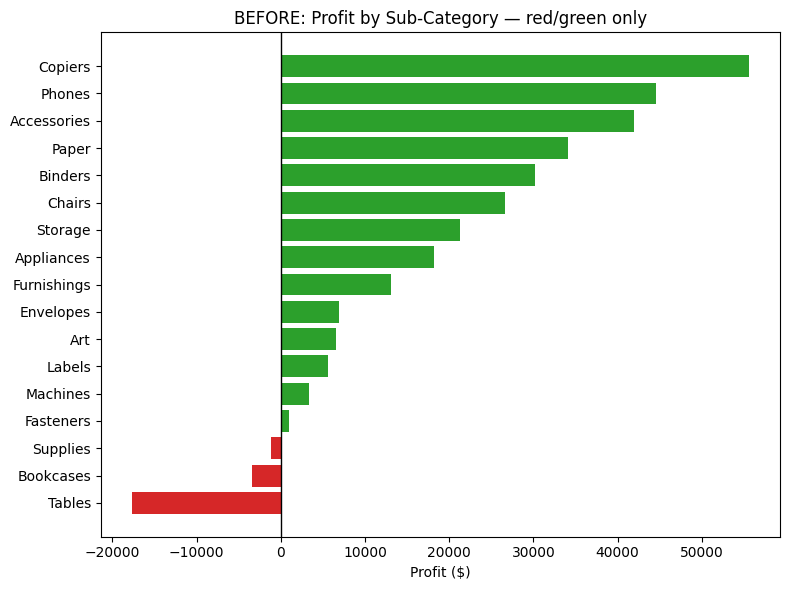

In [13]:
# Profit by sub-category, encoded with red (loss) vs green (gain) ONLY — the bad version
fig, ax = plt.subplots(figsize=(8, 6))
bad_colors = ['#D62728' if v < 0 else '#2CA02C' for v in subcat_profit.values]  # pure red/green
ax.barh(subcat_profit.index, subcat_profit.values, color=bad_colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('BEFORE: Profit by Sub-Category — red/green only')
ax.set_xlabel('Profit ($)')
plt.tight_layout()
plt.show()

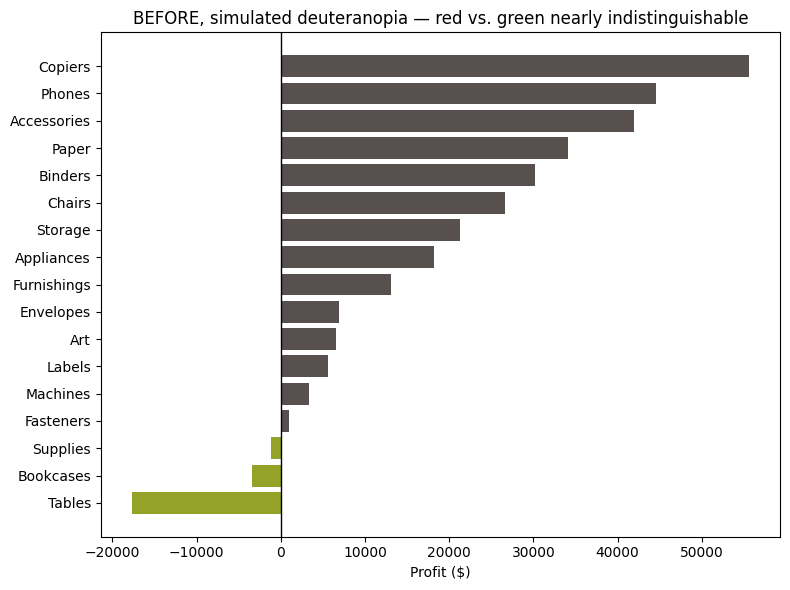

In [14]:
def simulate_deuteranopia(rgb):
    """Simple deuteranopia (red-green colorblindness) simulation matrix (Brettel-style approx)."""
    r, g, b = (c / 255 for c in rgb)
    r2 = 0.625 * r + 0.375 * g + 0.0 * b
    g2 = 0.7 * r + 0.3 * g + 0.0 * b
    b2 = 0.0 * r + 0.3 * g + 0.7 * b
    return tuple(np.clip([r2, g2, b2], 0, 1))

fig, ax = plt.subplots(figsize=(8, 6))
sim_colors = [simulate_deuteranopia(hex_to_rgb(c)) for c in bad_colors]
ax.barh(subcat_profit.index, subcat_profit.values, color=sim_colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('BEFORE, simulated deuteranopia — red vs. green nearly indistinguishable')
ax.set_xlabel('Profit ($)')
plt.tight_layout()
plt.show()

Running the red/green chart through the deuteranopia simulation confirms the accessibility
problem the manual warns about: the "loss" and "gain" bars simulate to very similar
brownish-olive tones, so a red-green colorblind reader (~8% of men) cannot reliably tell which
sub-categories are profitable just from color.

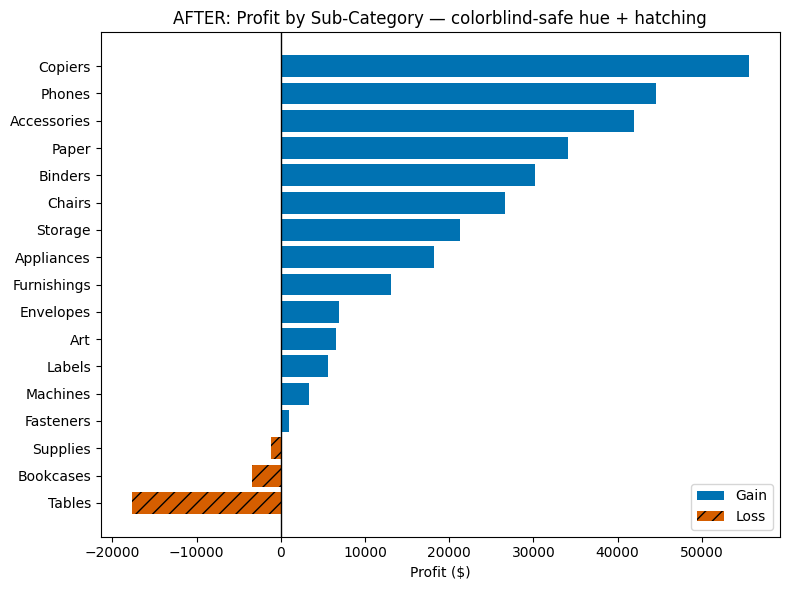

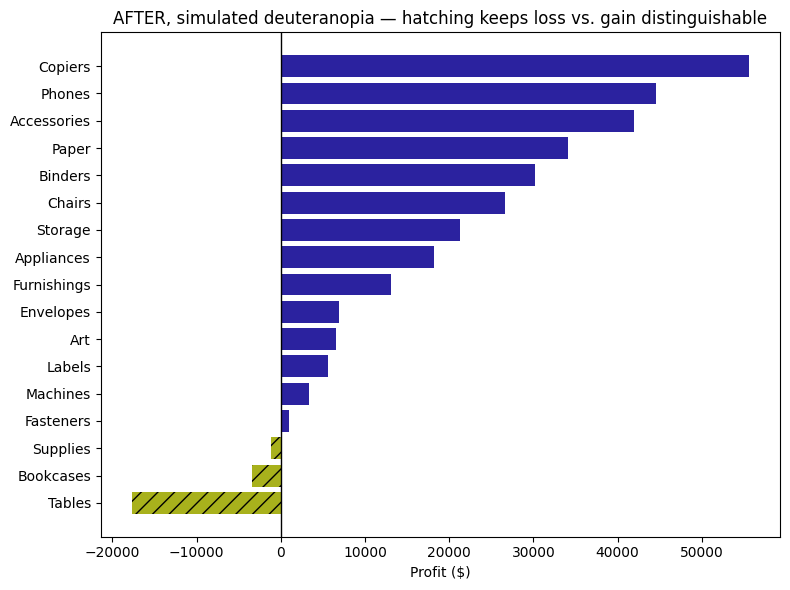

In [15]:
# AFTER: accessible fix — colorblind-safe hues + hatching so the distinction survives simulation
fig, ax = plt.subplots(figsize=(8, 6))
safe_colors = ['#D55E00' if v < 0 else '#0072B2' for v in subcat_profit.values]  # Okabe-Ito safe pair
hatches = ['//' if v < 0 else '' for v in subcat_profit.values]
bars = ax.barh(subcat_profit.index, subcat_profit.values, color=safe_colors)
for bar, h in zip(bars, hatches):
    bar.set_hatch(h)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('AFTER: Profit by Sub-Category — colorblind-safe hue + hatching')
ax.set_xlabel('Profit ($)')
legend_elems = [Patch(facecolor='#0072B2', label='Gain'),
                Patch(facecolor='#D55E00', hatch='//', label='Loss')]
ax.legend(handles=legend_elems, loc='lower right')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
sim_safe = [simulate_deuteranopia(hex_to_rgb(c)) for c in safe_colors]
bars = ax.barh(subcat_profit.index, subcat_profit.values, color=sim_safe)
for bar, h in zip(bars, hatches):
    bar.set_hatch(h)
ax.axvline(0, color='black', linewidth=1)
ax.set_title('AFTER, simulated deuteranopia — hatching keeps loss vs. gain distinguishable')
ax.set_xlabel('Profit ($)')
plt.tight_layout()
plt.show()

**Alt text:** "Horizontal bar chart of total profit by product sub-category, sorted from the
largest loss to the largest gain; loss bars are orange with diagonal hatching, gain bars are solid
blue, and a vertical line at zero marks the break-even point."

Even after the deuteranopia simulation, the hatched (loss) bars remain visually distinct from the
solid (gain) bars regardless of what hue they render as — the *pattern*, not the *color*, now
carries the meaning, exactly as the accessibility guidance in Section 3 recommends.

## Task 5 — Five misleading visualizations (distortion techniques)

### 5a. Truncated y-axis on the region sales chart

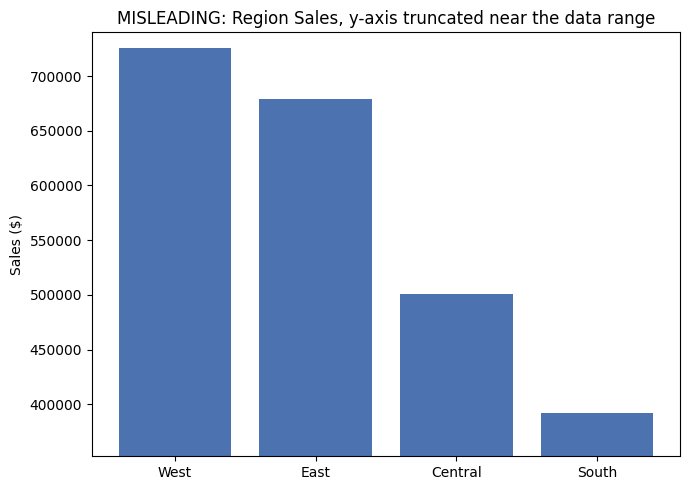

Distortion: the y-axis does not start at 0, so small real differences between regions
are stretched into what look like dramatic gaps in bar height.


In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(region_sales.index, region_sales.values, color='#4C72B0')
ax.set_ylim(region_sales.min() * 0.9, region_sales.max() * 1.02)
ax.set_title('MISLEADING: Region Sales, y-axis truncated near the data range')
ax.set_ylabel('Sales ($)')
plt.tight_layout()
plt.show()
print("Distortion: the y-axis does not start at 0, so small real differences between regions")
print("are stretched into what look like dramatic gaps in bar height.")

### 5b. Dual y-axes implying a fake correlation

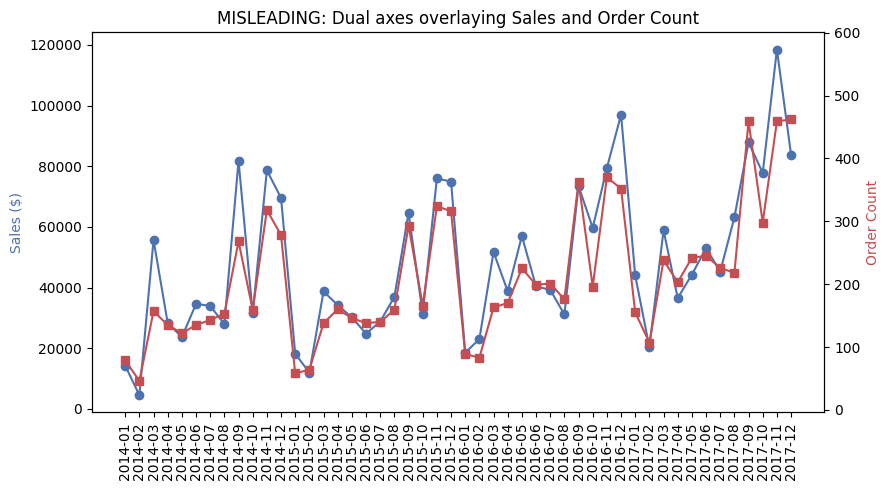

Distortion: two unrelated scales are overlaid and their ranges tuned so the lines
visually track each other, implying a tight correlation that the independent scales don't prove.


In [17]:
orders_per_month = df.set_index('Order Date').resample('MS').size()
orders_per_month.index = orders_per_month.index.strftime('%Y-%m')

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(monthly_sales.index, monthly_sales.values, color='#4C72B0', marker='o', label='Sales')
ax1.set_ylabel('Sales ($)', color='#4C72B0')
ax1.tick_params(axis='x', rotation=90)

ax2 = ax1.twinx()
ax2.plot(orders_per_month.index, orders_per_month.values, color='#C44E52', marker='s', label='Order count')
ax2.set_ylabel('Order Count', color='#C44E52')
ax2.set_ylim(orders_per_month.min() - 50, orders_per_month.max() * 1.3)  # scaled to force visual overlap

ax1.set_title('MISLEADING: Dual axes overlaying Sales and Order Count')
plt.tight_layout()
plt.show()
print("Distortion: two unrelated scales are overlaid and their ranges tuned so the lines")
print("visually track each other, implying a tight correlation that the independent scales don't prove.")

### 5c. Cherry-picked date window hiding the surrounding trend

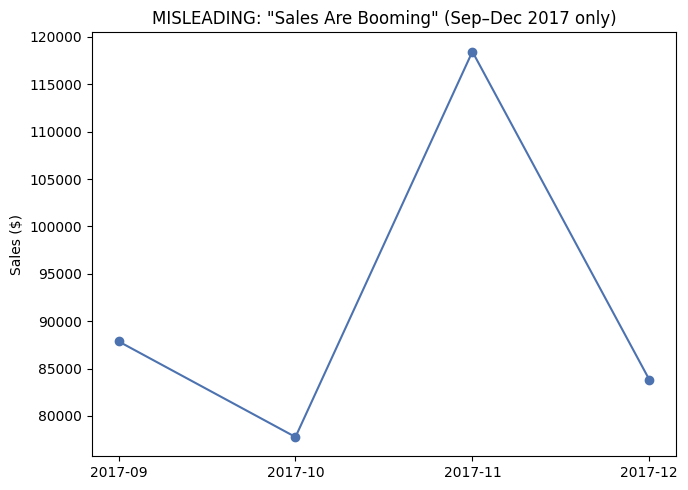

Distortion: cropping the timeline to only the strong end-of-year months manufactures
a growth story, while hiding the dips visible earlier in the full multi-year series.


In [18]:
recent = df[(df['Order Date'] >= '2017-09-01') & (df['Order Date'] <= '2017-12-31')]
recent_monthly = recent.set_index('Order Date')['Sales'].resample('MS').sum()
recent_monthly.index = recent_monthly.index.strftime('%Y-%m')

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(recent_monthly.index, recent_monthly.values, marker='o', color='#4C72B0')
ax.set_title('MISLEADING: "Sales Are Booming" (Sep–Dec 2017 only)')
ax.set_ylabel('Sales ($)')
plt.tight_layout()
plt.show()
print("Distortion: cropping the timeline to only the strong end-of-year months manufactures")
print("a growth story, while hiding the dips visible earlier in the full multi-year series.")

### 5d. Inverted y-axis on the monthly profit line

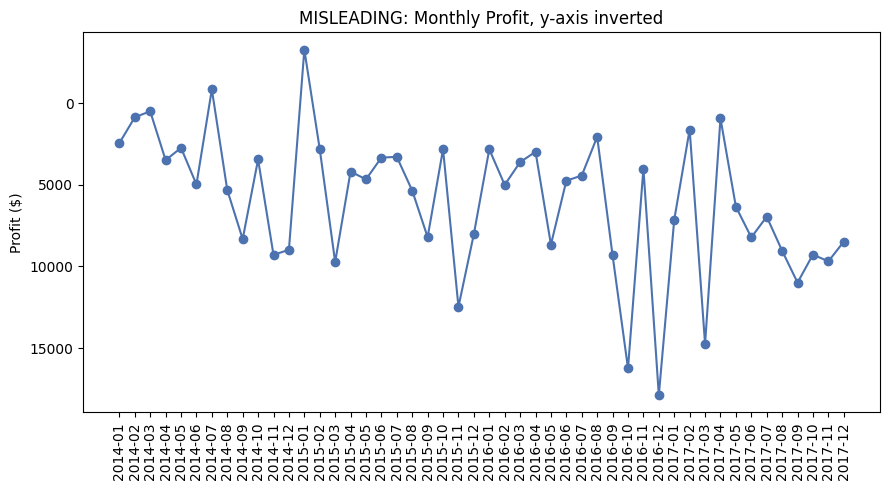

Distortion: flipping the y-axis makes rising profit visually plunge downward and vice versa,
reversing the apparent direction of the trend without changing a single data value.


In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(monthly_profit.index, monthly_profit.values, marker='o', color='#4C72B0')
ax.invert_yaxis()
ax.set_title('MISLEADING: Monthly Profit, y-axis inverted')
ax.set_ylabel('Profit ($)')
ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()
print("Distortion: flipping the y-axis makes rising profit visually plunge downward and vice versa,")
print("reversing the apparent direction of the trend without changing a single data value.")

### 5e. Bubble chart with radius (not area) scaled to value

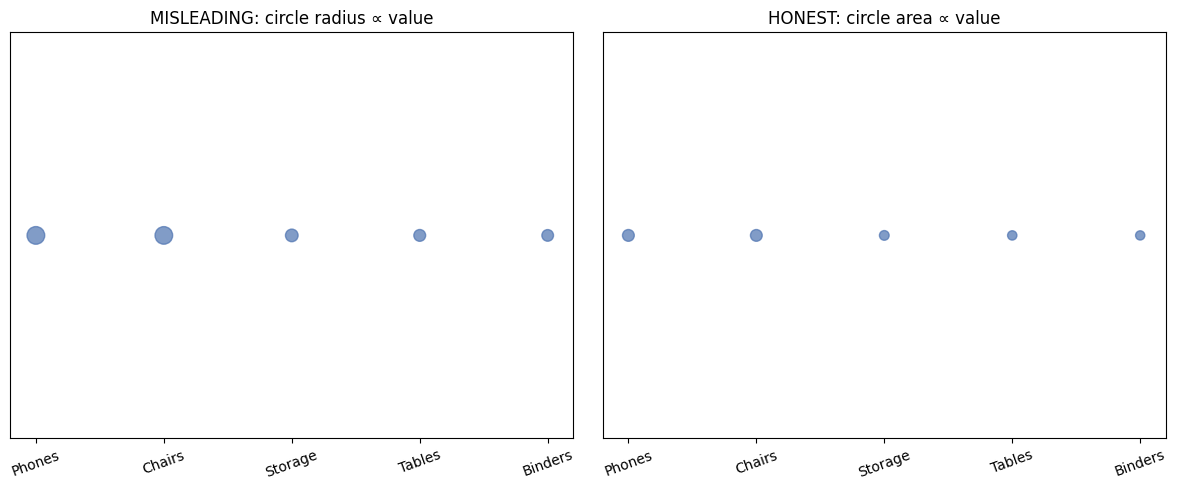

Distortion: when radius (not area) is scaled to value, a sub-category with 2x the sales
gets a circle with 4x the visual area, visually overstating how much bigger it really is.


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

x = np.arange(len(top5_subcat))
values = top5_subcat.values
max_val = values.max()

# Misleading: radius scales linearly with value -> area scales with value^2
radii_bad = 10 + 80 * (values / max_val)
axes[0].scatter(x, [1]*len(x), s=radii_bad**2 * 0.02, color='#4C72B0', alpha=0.7)
axes[0].set_title('MISLEADING: circle radius ∝ value')
axes[0].set_xticks(x); axes[0].set_xticklabels(top5_subcat.index, rotation=20)
axes[0].set_yticks([])

# Honest: area scales with value
radii_good = np.sqrt(values / max_val) * 60
axes[1].scatter(x, [1]*len(x), s=radii_good**2 * 0.02, color='#4C72B0', alpha=0.7)
axes[1].set_title('HONEST: circle area ∝ value')
axes[1].set_xticks(x); axes[1].set_xticklabels(top5_subcat.index, rotation=20)
axes[1].set_yticks([])

plt.tight_layout()
plt.show()
print("Distortion: when radius (not area) is scaled to value, a sub-category with 2x the sales")
print("gets a circle with 4x the visual area, visually overstating how much bigger it really is.")

## Task 6 — Case study: "Is discounting hurting profit?"
Using the raw `Discount` and `Profit` columns directly.

### Honest chart

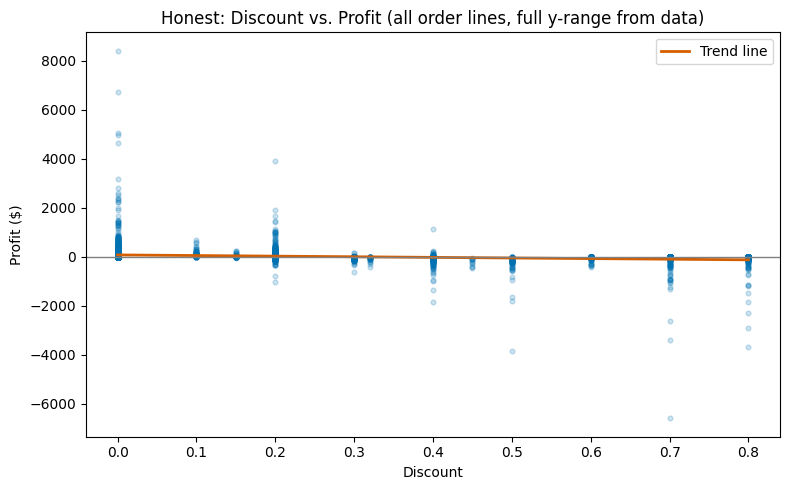

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['Discount'], df['Profit'], alpha=0.2, s=12, color='#0072B2')
z = np.polyfit(df['Discount'], df['Profit'], 1)
xs = np.linspace(df['Discount'].min(), df['Discount'].max(), 100)
ax.plot(xs, np.polyval(z, xs), color='#D55E00', linewidth=2, label='Trend line')
ax.axhline(0, color='gray', linewidth=1)
ax.set_title('Honest: Discount vs. Profit (all order lines, full y-range from data)')
ax.set_xlabel('Discount')
ax.set_ylabel('Profit ($)')
ax.legend()
plt.tight_layout()
plt.show()

### Deliberately misleading version

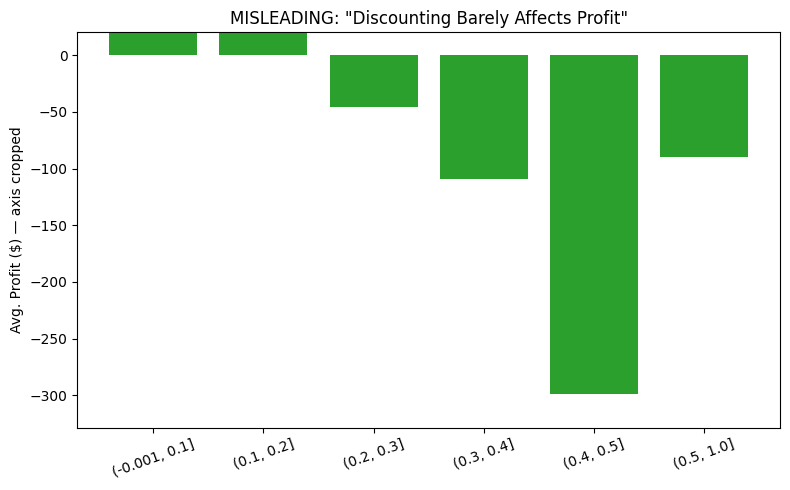

In [22]:
bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0]
df['discount_bin'] = pd.cut(df['Discount'], bins=bins, include_lowest=True)
avg_profit_by_bin = df.groupby('discount_bin', observed=True)['Profit'].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(avg_profit_by_bin.index.astype(str), avg_profit_by_bin.values, color='#2CA02C')
ax.set_ylim(avg_profit_by_bin.min() * 1.1, avg_profit_by_bin.max() * 0.3)  # truncated, cropped low end
ax.set_title('MISLEADING: "Discounting Barely Affects Profit"')
ax.set_ylabel('Avg. Profit ($) — axis cropped')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

### Written justification

**Chart type choice:** The honest chart uses a **scatter plot** because Discount and Profit are
both continuous, unaggregated variables measured per order line, and the analytical question is
about *correlation*, which scatter plots are built to reveal — the fitted trend line makes the
downward relationship explicit. The misleading version instead **aggregates into discount bins and
averages**, which throws away the variance and the many large individual losses at high discounts,
then **truncates the y-axis** to the top 30% of the range so the (already-smoothed) bars look
almost flat, manufacturing the false impression that discount level "barely affects" profit.

**Color choice:** The honest chart uses a colorblind-safe blue/orange pair (Okabe-Ito palette) —
points in blue, trend line in orange — so the two visual layers stay distinguishable without
relying on hue alone (the trend line is also thicker and a distinct style). The misleading chart
uses a single saturated green, which carries no extra information but reads as "good news,"
reinforcing the false takeaway.

**Accessibility check:** Both the point color (`#0072B2`) and trend-line color (`#D55E00`) in the
honest chart pass the WCAG contrast function from Task 4 against a white background, and the pair
was chosen from a deuteranopia-safe palette, so the distinction between raw points and the trend
line survives a red-green colorblindness simulation. The chart also does not rely on color alone —
line style/thickness separates the trend line from the point cloud independent of hue.

**Conclusion:** The honest chart shows that profit trends downward and turns negative as discount
increases, i.e., **discounting is associated with lower — and often negative — profit** in this
data; the binned/truncated version was built specifically to obscure that finding.

## Summary

| Task | What was produced |
|---|---|
| 1 | Bar / line / pie of monthly sales, with a written comparison |
| 2 | Bar, line, histogram, and scatter, each matched to its statement with justification |
| 3 | Categorical, sequential, and diverging palettes applied to region, region×category, and profit |
| 4 | WCAG contrast-ratio function + AA pass/fail table; red/green chart fixed with a colorblind-safe palette and hatching, verified against a deuteranopia simulation; alt text |
| 5 | Five misleading techniques reproduced, each captioned with the exact distortion mechanism |
| 6 | Honest vs. misleading chart answering "Is discounting hurting profit?" with full justification |

**Files submitted alongside this notebook:** `Superstore_cleaned.csv` (cleaned dataset).